In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
import json, pickle
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from tensorflow import keras
from keras.utils import set_random_seed
from keras.models import Model
from keras.optimizers import Adam
from keras.layers import Conv1D, Dropout, BatchNormalization, Activation, add, Bidirectional, LSTM, GRU, Input, Dense

In [ ]:
PICKLE_PATH = "/content/drive/MyDrive/proj/CopyDATA_MFCC30.pkl"

In [ ]:
def load_data():
    with open(PICKLE_PATH, "rb") as input:
        DATA = pickle.load(input)

    X = np.array(DATA["mfccs"], dtype=np.float32)
    y1 = np.array(DATA["labels"]["instrument"], dtype=np.int8)
    y2 = np.array(DATA["labels"]["scale"], dtype=np.int8)

    return X, y1, y2

In [ ]:
def tmp_load_data(num_data=9000):

    X = np.random.randn(num_data, 431, 45).astype(np.float64)
    y1 = np.random.randint(5, size=num_data, dtype=np.int32)
    y2 = np.random.randint(7, size=num_data, dtype=np.int32)

    return X, y1, y2

In [ ]:
def prepare_dataset():
    X, y1, y2 = load_data()

    X_train, X_test, y1_train, y1_test, y2_train, y2_test = \
        train_test_split(X, y1, y2, test_size=0.15, shuffle=True, random_state=0)

    X_test, X_val, y1_test, y1_val, y2_test, y2_val = \
        train_test_split(X_test, y1_test, y2_test, test_size=0.5, shuffle=True, random_state=0)

    return X_train, X_test, X_val, y1_train, y1_test, y1_val, y2_train, y2_test, y2_val

In [ ]:
def Residual_Conv1D(model, num_filters=512):

    def conv1D(model, dropout):
        model = Conv1D(filters=num_filters, kernel_size=5, padding='same')(model)
        model = Dropout(dropout)(model)
        model = BatchNormalization()(model)
        model = Activation('relu')(model)
        return model

    model_in = model

    model = conv1D(model, dropout=0.1)
    model = conv1D(model, dropout=0.2)

    shortcut = Conv1D(filters=num_filters, kernel_size=3, padding='same')(model_in)
    shortcut = BatchNormalization()(shortcut)

    model_out = add([shortcut, model])
    model_out = Activation('relu')(model_out)

    return model_out

In [ ]:
def Encoder(model):

    def BiLSTM(model, num_units, return_seq=True):
        model = Bidirectional(LSTM(units=num_units, return_sequences=return_seq))(model)
        model = BatchNormalization()(model)
        return model

    model = BiLSTM(model, num_units=256)
    model = BiLSTM(model, num_units=128)
    model = BiLSTM(model, num_units=64)

    return model

In [ ]:
def Decoder(model):

    def BiGRU(model, num_units, return_seq=True):
        model = Bidirectional(GRU(units=num_units, return_sequences=return_seq))(model)
        model = BatchNormalization()(model)
        return model

    model = BiGRU(model, num_units=32)
    model = BiGRU(model, num_units=64)
    model = BiGRU(model, num_units=128)
    model = BiGRU(model, num_units=256, return_seq=False)

    return model

In [ ]:
def FC_Dense(model, unit):
    model = Dense(units=unit, activation='relu', kernel_regularizer=keras.regularizers.l2(0.05))(model)
    model = Dropout(0.5)(model)

    return model

In [ ]:
def Output(models):
    y1_output = Dense(units=5, activation='softmax', name='instrument')(models[0])
    y2_output = Dense(units=7, activation='softmax', name='scale')(models[1])

    return (y1_output, y2_output)

In [ ]:
def build_model(input_shape) -> Model:

    input = Input(input_shape)
    model = Residual_Conv1D(input)
    model = Encoder(model)
    model = Decoder(model)
    model_1 = FC_Dense(model, unit=16)
    model_2 = FC_Dense(model, unit=24)
    output = Output((model_1, model_2))
    model = Model(inputs=input, outputs=output)

    return model

In [ ]:
X_train, X_test, X_val, y1_train, y1_test, y1_val, y2_train, y2_test, y2_val = prepare_dataset()
Y_train = (y1_train, y2_train)
Y_test = (y1_test, y2_test)
Y_val = (y1_val, y2_val)

del y1_train, y1_test, y1_val, y2_train, y2_test, y2_val

In [ ]:
set_random_seed(0)
model = build_model(input_shape=(X_train.shape[1], X_train.shape[2]))
# model.summary()

optimizer = Adam(learning_rate=0.001)
model.compile(
    optimizer=optimizer,
    loss={
        'instrument': 'sparse_categorical_crossentropy',
        'scale': 'sparse_categorical_crossentropy'
    },
    metrics={
        'instrument': ['accuracy'],
        'scale': ['accuracy']
    }
)

history = model.fit(X_train, Y_train,
                    validation_data=(X_val, Y_val),
                    batch_size=128,
                    epochs=130)

Epoch 1/130
60/60 [==============================] - 59s 478ms/step - loss: 5.9077 - instrument_loss: 0.8592 - scale_loss: 2.1322 - instrument_accuracy: 0.6698 - scale_accuracy: 0.2013 - val_loss: 5.0563 - val_instrument_loss: 1.0629 - val_scale_loss: 1.9367 - val_instrument_accuracy: 0.6908 - val_scale_accuracy: 0.1657
Epoch 2/130
60/60 [==============================] - 25s 417ms/step - loss: 3.7170 - instrument_loss: 0.4499 - scale_loss: 1.7659 - instrument_accuracy: 0.8200 - scale_accuracy: 0.2918 - val_loss: 3.3860 - val_instrument_loss: 0.5285 - val_scale_loss: 1.8234 - val_instrument_accuracy: 0.8343 - val_scale_accuracy: 0.2855
Epoch 3/130
60/60 [==============================] - 26s 431ms/step - loss: 2.7178 - instrument_loss: 0.3585 - scale_loss: 1.6028 - instrument_accuracy: 0.8663 - scale_accuracy: 0.3694 - val_loss: 2.3762 - val_instrument_loss: 0.2640 - val_scale_loss: 1.5810 - val_instrument_accuracy: 0.9393 - val_scale_accuracy: 0.4068
Epoch 4/130
60/60 [===============

In [ ]:
loss, instrument_loss, scale_loss, instrument_accuracy, scale_accuracy = model.evaluate(X_test, Y_test)
print(f"\nTest Results:\n")
print(f"Total Loss: {loss}")
print(f"Instrument Loss: {instrument_loss}")
print(f"Scale Loss: {scale_loss}")
print(f"Instrument Accuracy on Test Set: {instrument_accuracy}")
print(f"Scale Accuracy on Test Set: {scale_accuracy}")

22/22 [==============================] - 2s 66ms/step - loss: 0.4785 - instrument_loss: 0.1033 - scale_loss: 0.3165 - instrument_accuracy: 0.9867 - scale_accuracy: 0.9437

Test Results:

Total Loss: 0.47849369049072266
Instrument Loss: 0.10326997935771942
Scale Loss: 0.31650787591934204
Instrument Accuracy on Test Set: 0.9866666793823242
Scale Accuracy on Test Set: 0.9437037110328674


In [ ]:
def plot_history(history):

    def plot_result(metrics, labels, y_label, title, location):
        plt.plot(history.history[metrics[0]], label=labels[0])
        plt.plot(history.history[metrics[1]], label=labels[1])
        plt.title(title)
        plt.xlabel("Epoch")
        plt.ylabel(y_label)
        plt.legend(loc=location)
        plt.savefig("/content/drive/MyDrive/proj/pic/MFCC_B128_E130_M30/" + title + ".png")
        plt.show()
        print("\n\n")

    # create accuracy sublpot
    plot_result(metrics=("instrument_accuracy", "val_instrument_accuracy"),
                 labels=("Instrument Train Accuracy", "Instrument Test Accuracy"),
                 y_label="Accuracy", title="Instrument Accuracy Evaluation", location="lower right")

    plot_result(metrics=("instrument_loss", "val_instrument_loss"),
                 labels=("Instrument Train Error", "Instrument Test Error"),
                 y_label="Loss", title="Instrument Error Evaluation", location="upper right")

    plot_result(metrics=("scale_accuracy", "val_scale_accuracy"),
                 labels=("Scale Train Accuracy", "Scale Test Accuracy"),
                 y_label="Accuracy", title="Scale Accuracy Evaluation", location="lower right")

    plot_result(metrics=("scale_loss", "val_scale_loss"),
                 labels=("Scale Train Error", "Scale Test Error"),
                 y_label="Loss", title="Scale Error Evaluation", location="upper right")

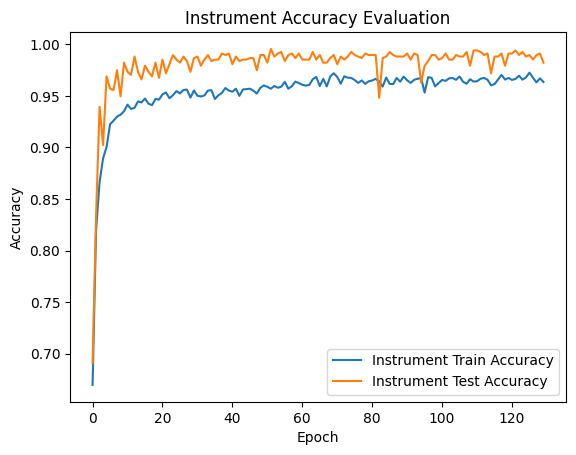

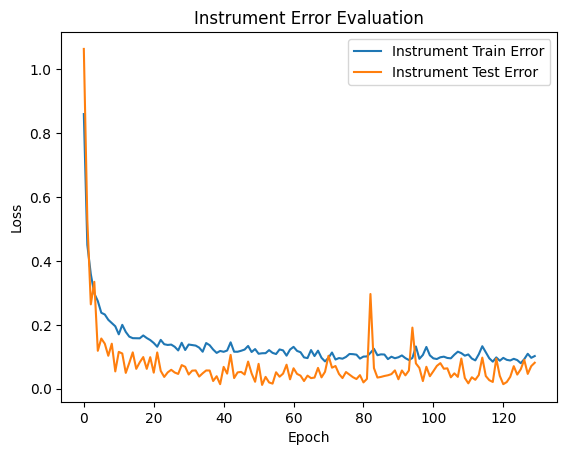

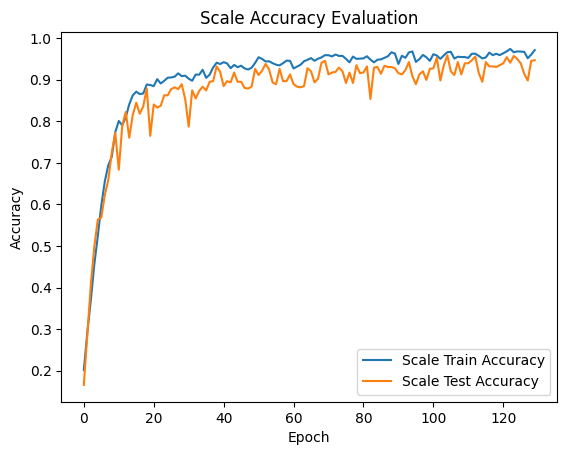

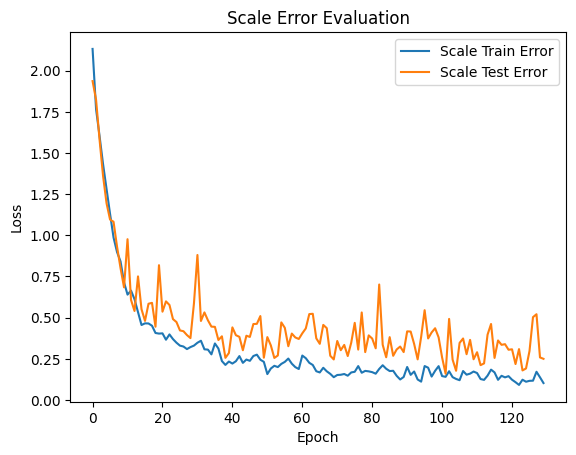

In [ ]:
plot_history(history)

In [ ]:
# model.save(filepath="/content/drive/MyDrive/proj/models/MFCC_B128_E130_M30")